# **MÓDULO 21 - Projeto de Credit Score - Árvore de Decisão**


No módulo 17, vocês realizaram a primeira etapa do projeto de crédito de vocês. Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste. Já no módulo 14, aplicaram a base já tratada o algoritmo de Naive Bayes, onde avaliaram os resultados das previsões. Nesse módulo aplicaremos a nossa base o algoritmo da árvore de decisão.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [5]:
#seu código aqui
# Carregamento das bases de dados

X_test = pd.read_csv('../data/processed/X_test.csv', delimiter=',')
X_train = pd.read_csv('../data/processed/X_train_balanced.csv', delimiter=',')
y_test = pd.read_csv('../data/processed/y_test.csv', delimiter=',')
y_train = pd.read_csv('../data/processed/y_train_balanced.csv', delimiter=',')

In [11]:
y_train.head(10)

,Credit Score
0,1
1,0
2,1
3,0
4,1
5,1
6,2
7,1
8,1
9,1


In [12]:
y_test.head(10)

,Credit Score
0,1
1,0
2,1
3,1
4,1
5,1
6,1
7,2
8,1
9,1


In [13]:
X_test.head(10)

,Age,Income,Number of Children,Education_encoded,Marital Status_Single,Home Ownership_Rented,Gender_Male
0,37.208,67500.0,2,1,False,False,False
1,34.000,47500.0,0,0,True,True,True
2,32.000,85000.0,0,4,True,True,True
3,49.000,77500.0,1,2,False,False,False
4,50.000,162500.0,0,4,False,False,True
5,30.000,105000.0,2,4,False,False,True
6,37.208,130000.0,0,3,False,False,True
7,29.000,27500.0,0,3,True,True,False
8,41.000,120000.0,0,2,True,False,True
9,37.208,140000.0,0,1,False,False,True


In [15]:
X_train.head(10)

,Age,Income,Number of Children,Education_encoded,Marital Status_Single,Home Ownership_Rented,Gender_Male
0,44.000,75000.0,0,4,True,False,True
1,31.000,65000.0,0,1,True,True,True
2,37.208,90000.0,1,2,False,False,False
3,25.000,62500.0,0,1,True,True,False
4,36.000,90000.0,2,4,False,False,False
5,41.000,110000.0,0,2,True,False,True
6,37.208,27500.0,0,3,True,True,False
7,53.000,115000.0,0,0,False,False,True
8,37.208,87500.0,0,4,True,False,True
9,37.208,125000.0,0,0,False,False,True


# 2) Explique com suas palavras, qual o passo a passo para a aplicação do algoritmo da árvore de decisão, não esqueça de citar a etapa de avaliação do modelo e também como podemos melhorar nosso modelo.

## Justificativa

Primeiramente, é necessário realizar uma exploração dos dados. Analisar a nossa base, analisar as variáveis e os tipos das variáveis para que possamos compreender e tentar tirar algum insight para saber se existe alguma correlação entre dos dados.

Em seguida, fazemos o pré-processamento. Nesta etapa devemos padronizar o DataFrame, alterar os tipos das variáveis, eliminar colunas desnecessárias, tratar os dados para que estes estejam consistentes, e então realizar as conversões para aplicar funções numéricas e analisar. Essa etapa nos ajuda a realizar a normalização e padronização dos dados.

Depois, realizamos as análises univaridas e bivariadas para que seja seja feito um segundo tratamento, caso necessário. Essa etapa também nos trás importantes insights, e nos permite analisar se existe correlação entre as variáveis ou se existe outliers nas nossas bases.

Por fim, chegamos na parte em que devemos aplicar ao nosso modelo. No caso da árvore decisão, basta implementar o algorítmo de treino pelo critário de Gini ou de Entropia, analisar os parâmetros da árvore de decisão e configurá-la da melhor forma, e então avaliar os resultados.

# 3) Aplique o algortimo da árvore de decisão aos dados de treinamento, utilizando critério de Gini e random state = 0.
Traga a acurácia para o modedlo com os dados de treino.

In [21]:
#seu código aqui
tree_decision = DecisionTreeClassifier(criterion='gini', random_state=0)
tree_decision.fit(X_train, y_train.values.ravel())

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

In [22]:
#seu código aqui
previsoes = tree_decision.predict(X_test)
acuracia = accuracy_score(y_test, previsoes)
print('Acurácia: ', acuracia)

Acurácia:  0.975


In [23]:
relatorio = classification_report(y_test, previsoes)
print('Relatório de Classificação: ')
print(relatorio)

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.90      1.00      0.95         9
           1       1.00      0.96      0.98        27
           2       1.00      1.00      1.00         4

    accuracy                           0.97        40
   macro avg       0.97      0.99      0.98        40
weighted avg       0.98      0.97      0.98        40



## Justificativa

Como podemos ver, os dados tiveram altíssima precisão, acurácia e recall. O modelo se ajusta bem à essa base de dados. Se mostrou perfeita para a classificar a classe '2'.

# 5) Plote a árvore de decisão.
É possível fazer uma avaliação visual? Qual a profundidade da árvore?

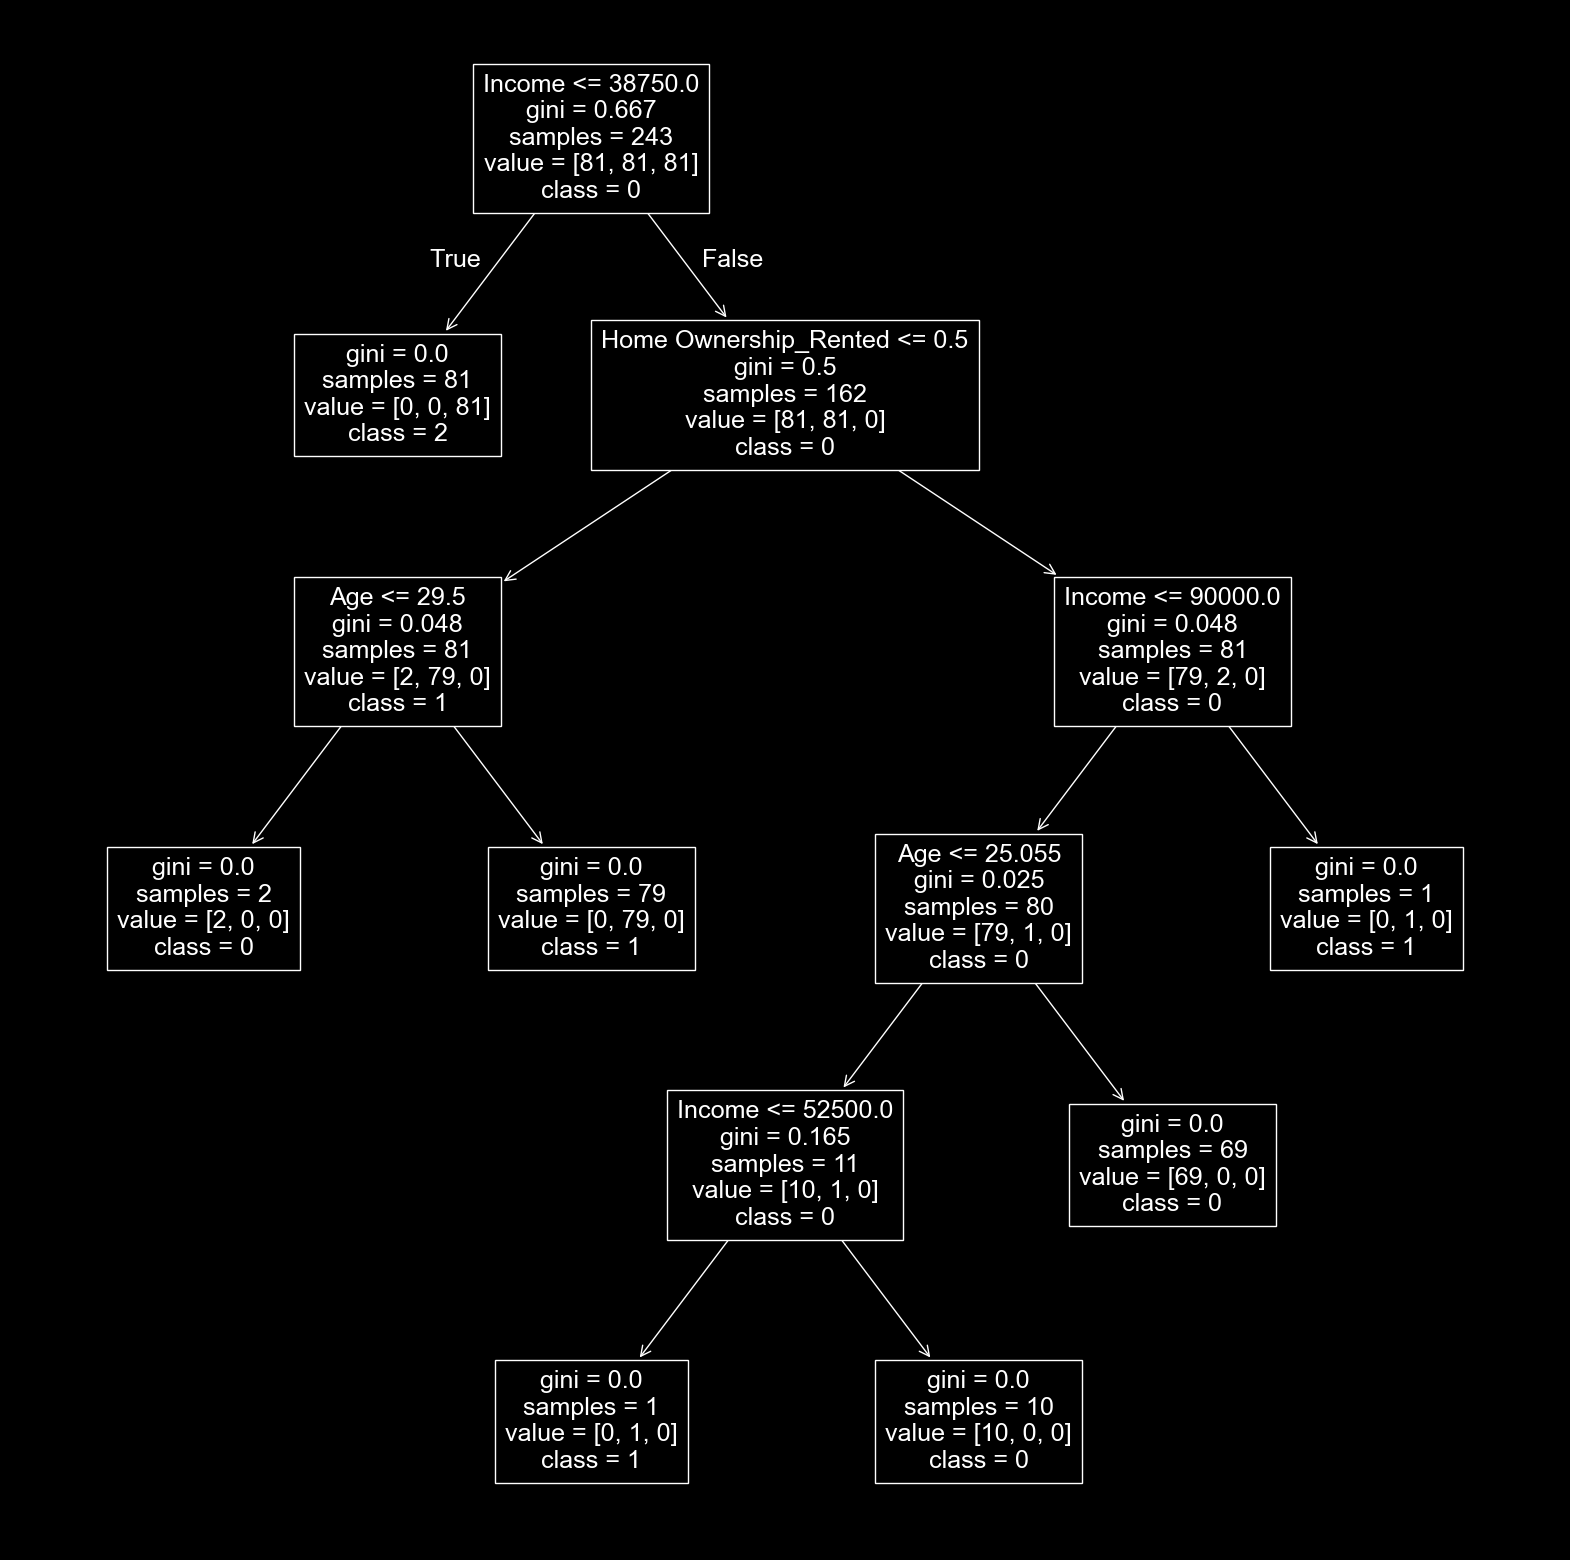

In [25]:
#seu código aqui
plt.figure(figsize=(20,20))
plot_tree(tree_decision, feature_names=X_train.columns, class_names=['0', '1', '2'])
plt.show()

## Justificativa

É possível sim! É visualmente bem elegante, e apresenta uma profundidade 7

# 6) Identifique as 2 principais features do modelo.


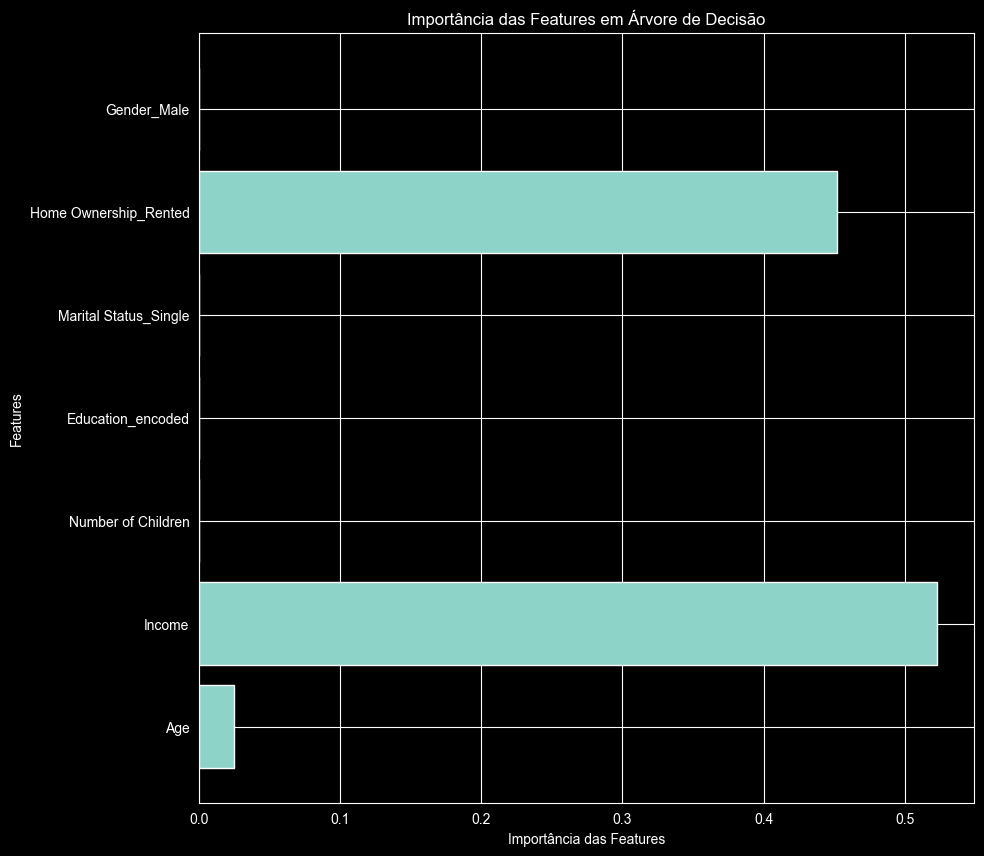

In [26]:
#seu código aqui

# Obtendo a importância das características do modelo de árvore de decisão
importancias_features = tree_decision.feature_importances_

# Obtendo os nomes das características
nomes_features = X_train.columns

plt.figure(figsize=(10,10))
plt.barh(nomes_features, importancias_features)
plt.xlabel('Importância das Features')
plt.ylabel('Features')
plt.title('Importância das Features em Árvore de Decisão')
plt.show()

## Justificativa

As duas principais categorias são: 'Income' e 'Home Ownership_Rented'

# 7) Rode um modelo de árvore de decisão apenas com as 2 principais features encontradas. E avalie os resultados. Para você o desempenho da árvore está melhor que o modelo anterior? Justifique.

In [27]:
#seu código aqui
X_train_reduzido = X_train[['Home Ownership_Rented', 'Income']]
X_test_reduzido = X_test[['Home Ownership_Rented', 'Income']]

In [28]:
tree_decision_reduced = DecisionTreeClassifier(criterion='gini', random_state=0)
tree_decision_reduced.fit(X_train_reduzido, y_train.values.ravel())

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

In [29]:
previsoes_reduzido = tree_decision_reduced.predict(X_test_reduzido)

In [31]:
relatorio = classification_report(y_test, previsoes_reduzido)
print('Relatório de Classificação: ')
print(relatorio)

Relatório de Classificação: 
              precision    recall  f1-score   support

           0       0.88      0.78      0.82         9
           1       0.93      0.96      0.95        27
           2       1.00      1.00      1.00         4

    accuracy                           0.93        40
   macro avg       0.93      0.91      0.92        40
weighted avg       0.92      0.93      0.92        40



## Justificativa

O desempenho desse modelo não foi melhor que o anterior. Foi excekente também, porém para a classe '0', houve um leve decaimento.

# 8) Compare os resultados obtidos com a árvore de decisão com os resultados do Naive Bayes (Exercício módulo 20). Qual parece ter se adequado melhor aos dados e tem melhores resultados de avaliação? Justifique.

## Justificativa
Ambos os modelos se saíram muito bem, tanto em termos de acurácia e recall. O Modelo de Naive Bayes só ficou atrás por pouquíssima coisa. Porém, o modelo de árvore de decisão, por ser mais menos custoso computacionalmente e mais 'visível', este modelo leva vantagem